# Explicación del Dataset


**Online Payments Fraud Detection Dataset**

Este dataset está diseñado para la tarea de detección de fraude en transacciones de pagos en línea. Contiene un volumen masivo de datos transaccionales que simulan el flujo de dinero entre diferentes cuentas.

Aunque, al revisar en Kaggle, explícitamente no se menciona, pero varios indicios sugieren que el dataset es simulado:



*   Columna "step": Representa el tiempo en horas discretas, algo común en     simulaciones. En sistemas reales, el tiempo se mide con timestamps precisos.
*   Privacidad: Es poco probable que datos reales de fraude bancario, por su sensibilidad, se publiquen con tanto detalle sin recurrir a simulaciones.
*   Columna "isFlaggedFraud": Indica un sistema de detección automatizado propio del entorno simulado, basado en reglas predefinidas.


Características del Dataset:

El dataset incluye las siguientes columnas, que describen cada transacción:



1.   **step:** Representa una unidad de tiempo en la simulación, donde 1 step equivale a 1 hora. Es un valor numérico entero que indica la hora en que ocurrió la transacción.
2.   **type:** El tipo de transacción en línea. Es una característica categórica que puede tomar los siguientes valores:
       
    *   **PAYMENT:** Transacción de dinero de un cliente a un comerciante (ej., compra de un producto o servicio).
    *   **TRANSFER:** Movimiento de dinero de una cuenta de cliente a otra cuenta de cliente. En este dataset, el fraude solo ocurre en transacciones de tipo TRANSFER y CASH_OUT.
    *   **CASH_OUT:** una transacción donde el dinero es retirado o sacado de una cuenta de cliente para ser convertido en efectivo o para transferirlo a un medio que facilita su retiro físico.
    *   **DEBIT:** Débito directo de la cuenta de un cliente para un pago o servicio.
    *   **CASH_IN:** Depósito de dinero en una cuenta de cliente.
3.   **amount:** El monto monetario de la transacción. Es un valor numérico flotante.
4.   **nameOrig:** Identificador del cliente que inicia la transacción (origen del dinero). Son IDs anonimizados (ej., 'C12345').
3.   **oldbalanceOrg:** Saldo del cliente que inicia la transacción antes de que se realice la misma. Es un valor numérico flotante.
4.   **newbalanceOrig:** Saldo del cliente que inicia la transacción después de que se realiza la misma. Es un valor numérico flotante.
3.   **nameDest:** Identificador del destinatario de la transacción (receptor del dinero). También son IDs anonimizados (ej., 'M98765' para comerciantes, 'C12345' para otros clientes).
4.   **oldbalanceDest:** Saldo inicial del destinatario antes de recibir el dinero. Es un valor numérico flotante.
3.   **newbalanceDest:** Nuevo saldo del destinatario después de recibir el dinero. Es un valor numérico flotante.
4.   **isFraud:** La variable objetivo principal. Es una columna binaria que indica si la transacción fue fraudulenta (1) o legítima (0).
3.   **isFlaggedFraud:** Esta columna indica si la transacción fue marcada como sospechosa de fraude por un sistema de monitoreo interno preexistente en el simulador. Es una bandera binaria (1 si fue marcada, 0 si no). Es importante distinguirla de isFraud, que es la verdad fundamental del fraude.


# Preprocesamiento del Dataset

El data set encontrado tiene más de 6 millones de filas, lo cúal comprometería significativamente el tiempo de ejecución, por lo tanto se decidió recortar el data set a 8 mil registros, para evitar el cesgo, realizamos un muestreo estratificado asegurando que la proporción de la clase objetivo (la cúal es muy pequeña dado que estamos trabajando con fraudes) se mantenga.

## Carga del Dataset

In [ ]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.utils import resample
import os

In [ ]:
# Download latest version
path = kagglehub.dataset_download("rupakroy/online-payments-fraud-detection-dataset")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/online-payments-fraud-detection-dataset


In [ ]:
# Nombre del archivo .csv sacado de Kaggle y guardado en la máquina virtual de Google Colab:

csv_file_name = "PS_20174392719_1491204439457_log.csv"

# Construimos la ruta completa al archivo CSV
full_csv_path = os.path.join(path, csv_file_name)

In [ ]:
df_full = pd.read_csv(full_csv_path)
print(f"\nDataset completo cargado exitosamente. Número total de registros: {len(df_full)}")
print("Primeras 5 filas del dataset:")
print(df_full.head())
print("\nInformación del dataset:")
df_full.info()


Dataset completo cargado exitosamente. Número total de registros: 6362620
Primeras 5 filas del dataset:
   step      type    amount     nameOrig  oldbalanceOrg  newbalanceOrig  \
0     1   PAYMENT   9839.64  C1231006815       170136.0       160296.36   
1     1   PAYMENT   1864.28  C1666544295        21249.0        19384.72   
2     1  TRANSFER    181.00  C1305486145          181.0            0.00   
3     1  CASH_OUT    181.00   C840083671          181.0            0.00   
4     1   PAYMENT  11668.14  C2048537720        41554.0        29885.86   

      nameDest  oldbalanceDest  newbalanceDest  isFraud  isFlaggedFraud  
0  M1979787155             0.0             0.0        0               0  
1  M2044282225             0.0             0.0        0               0  
2   C553264065             0.0             0.0        1               0  
3    C38997010         21182.0             0.0        1               0  
4  M1230701703             0.0             0.0        0               0  


## Muestreo Estratificado

In [ ]:
# Dataset completo cargado
# Use the 'python' engine as it's more robust to parsing errors
try:
    # Definir la variable objetivo
    target_column = 'isFraud'

    # Verificar la distribución de la clase objetivo para estratificar
    print("Distribución de 'isFraud' en el dataset completo:")
    print(df_full[target_column].value_counts(normalize=True))

except pd.errors.ParserError as e:
    print(f"Error reading the CSV file: {e}")
    print("Please check the file for inconsistencies, particularly around line 15122.")
    df_full = None # Ensure df_full is None if reading fails

Distribución de 'isFraud' en el dataset completo:
isFraud
0    0.998709
1    0.001291
Name: proportion, dtype: float64


In [ ]:
# Realizar un muestreo estratificado
# Definimos el tamaño de la muestra que queremos (8000 registros)
sample_size = 8000

# Dividimos el dataset en dos partes: la muestra y el resto.
# stratify=df_full[target_column] asegura que la proporción de 'isFraud' se mantenga en la muestra.
if len(df_full) > sample_size:
    df_sampled, _ = train_test_split(
        df_full,
        train_size=sample_size,
        stratify=df_full[target_column],
        random_state=42 # Para reproducibilidad
    )
    print(f"\nDataset muestreado a {len(df_sampled)} registros.")
    print("Distribución de 'isFraud' en el dataset muestreado:")
    print(df_sampled[target_column].value_counts(normalize=True))
else:
    df_sampled = df_full
    print("\nEl dataset es más pequeño que el tamaño de muestra deseado. Usando el dataset completo.")


Dataset muestreado a 8000 registros.
Distribución de 'isFraud' en el dataset muestreado:
isFraud
0    0.99875
1    0.00125
Name: proportion, dtype: float64


## Eliminación de Columnas Innecesarias

Para el análisis y entrenamiento del modelo de clasificación de fraude, se decidió eliminar algunas columnas que no aportan valor predictivo o podrían inducir sesgos. La columna step, aunque representa el tiempo, es artificial y no aporta beneficios significativos al no trabajar con series temporales. isFlaggedFraud refleja un sistema de detección preexistente y usarla podría hacer que el modelo simplemente lo replique. Finalmente, nameOrig y nameDest son identificadores únicos de alta cardinalidad, que no contienen información útil por sí mismos y podrían sesgar el modelo hacia la memorización de cuentas específicas.

Columnas eliminadas:



*   step
*   isFlaggedFraud
*   nameOrig
*   nameDest

In [ ]:
# --- PASO 4: Eliminar las columnas no necesarias ---
columns_to_drop = ['step', 'isFlaggedFraud', 'nameOrig', 'nameDest']

# Usamos .copy() para asegurarnos de trabajar con una copia y evitar SettingWithCopyWarning
df_processed = df_sampled.drop(columns=columns_to_drop).copy()

print(f"\nColumnas eliminadas: {columns_to_drop}")
print("Columnas restantes en el dataset procesado:")
print(df_processed.columns)
print(f"Nuevo shape del dataset: {df_processed.shape}")
print("\nPrimeras 5 filas del dataset procesado (después de eliminar columnas):")
print(df_processed.head())

# Ahora, 'df_processed' es el DataFrame con el que continuaremos


Columnas eliminadas: ['step', 'isFlaggedFraud', 'nameOrig', 'nameDest']
Columnas restantes en el dataset procesado:
Index(['type', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest',
       'newbalanceDest', 'isFraud'],
      dtype='object')
Nuevo shape del dataset: (8000, 7)

Primeras 5 filas del dataset procesado (después de eliminar columnas):
             type     amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  \
3796279   CASH_IN   41400.85     3023365.88      3064766.74       174415.98   
352490   CASH_OUT   69739.67           0.00            0.00        91140.29   
5125883  CASH_OUT  322403.78           0.00            0.00      9151852.31   
2809798  CASH_OUT   93336.93           0.00            0.00       172023.54   
2607285  CASH_OUT  132684.15       27088.95            0.00       310278.10   

         newbalanceDest  isFraud  
3796279       133015.13        0  
352490        160879.96        0  
5125883      9474256.09        0  
2809798       265360.47 

## Verificación de Datos Nulos

In [ ]:
missing = df_processed.isnull().sum()
missing

,0
type,0
amount,0
oldbalanceOrg,0
newbalanceOrig,0
oldbalanceDest,0
newbalanceDest,0
isFraud,0


## Búsqueda y Eliminación de Filas Duplicadas

In [ ]:
dupli =  df_processed.duplicated().sum()
dupli

np.int64(1)

In [ ]:
duplicate_rows_all_occurrences = df_processed[df_processed.duplicated()]
print("\n--- Todas las ocurrencias de filas que tienen duplicados ---")
print(f"Número total de ocurrencias duplicadas: {len(duplicate_rows_all_occurrences)}")
print(duplicate_rows_all_occurrences.sort_values(by=list(df_processed.columns)).head(10))


--- Todas las ocurrencias de filas que tienen duplicados ---
Número total de ocurrencias duplicadas: 1
           type  amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  \
906204  PAYMENT  191.74            0.0             0.0             0.0   

        newbalanceDest  isFraud  
906204             0.0        0  


In [ ]:
# Eliminar las filas duplicadas
# keep='first' (valor por defecto) mantiene la primera ocurrencia y elimina las subsiguientes.


print(f"\nShape del dataset antes de la eliminación de filas: {df_processed.shape}.")
df_no_duplicates = df_processed.drop_duplicates(keep='first').copy()

num_duplicates_after = df_no_duplicates.duplicated().sum() # Debería ser 0
print(f"Número de filas duplicadas después de la eliminación: {num_duplicates_after}")

print(f"Shape del dataset después de eliminar duplicados: {df_no_duplicates.shape}")
print("\nPrimeras 5 filas del dataset después de eliminar duplicados:")
print(df_no_duplicates.head())

# Ahora, 'df_no_duplicates' es el DataFrame con el que continuarás.
# Puedes renombrarlo a 'df_clean' o 'df_final' para mayor claridad.



Shape del dataset antes de la eliminación de filas: (8000, 7).
Número de filas duplicadas después de la eliminación: 0
Shape del dataset después de eliminar duplicados: (7999, 7)

Primeras 5 filas del dataset después de eliminar duplicados:
             type     amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  \
3796279   CASH_IN   41400.85     3023365.88      3064766.74       174415.98   
352490   CASH_OUT   69739.67           0.00            0.00        91140.29   
5125883  CASH_OUT  322403.78           0.00            0.00      9151852.31   
2809798  CASH_OUT   93336.93           0.00            0.00       172023.54   
2607285  CASH_OUT  132684.15       27088.95            0.00       310278.10   

         newbalanceDest  isFraud  
3796279       133015.13        0  
352490        160879.96        0  
5125883      9474256.09        0  
2809798       265360.47        0  
2607285       442962.25        0  


## Creación de 5 Clases para la Variable Objetivo

Para cumplir con el requisito de tener al menos 4 clases y enriquecer el análisis, dividí la clase de fraude en 5 categorías según el tipo de transacción y el monto involucrado. Esta segmentación permite capturar no solo la presencia de fraude, sino también su naturaleza y gravedad, lo cual es relevante para posibles respuestas diferenciadas.

Clases definidas:

Transacción legítima

Fraude en transferencia de bajo monto

Fraude en transferencia de alto monto

Fraude en retiro (cash out) de bajo monto

Fraude en retiro (cash out) de alto monto

La separación por monto se hizo usando la mediana como umbral, lo que permite analizar el rendimiento de los modelos por tipo y magnitud de fraude.

In [ ]:
# Identificar la variable objetivo original
original_target_column = 'isFraud'

#Calcular los umbrales para los montos de fraude

# Umbral para FRAUDE TIPO TRANSFER
fraud_transfer_amounts = df_no_duplicates[(df_no_duplicates['isFraud'] == 1) & (df_no_duplicates['type'] == 'TRANSFER')]['amount']
if not fraud_transfer_amounts.empty:
    amount_threshold_transfer = fraud_transfer_amounts.median()
    print(f"Umbral de monto para fraude TIPO TRANSFER (mediana): {amount_threshold_transfer:.2f}")
else:
    amount_threshold_transfer = 0 # Valor por defecto si no hay TRANSFER fraudulentos
    print("No se encontraron transacciones TRANSFER fraudulentas para calcular el umbral. Estableciendo umbral de transferencia a 0.")

# Umbral para FRAUDE TIPO CASH_OUT
fraud_cashout_amounts = df_no_duplicates[(df_no_duplicates['isFraud'] == 1) & (df_no_duplicates['type'] == 'CASH_OUT')]['amount']
if not fraud_cashout_amounts.empty:
    amount_threshold_cashout = fraud_cashout_amounts.median()
    print(f"Umbral de monto para fraude TIPO CASH_OUT (mediana): {amount_threshold_cashout:.2f}")
else:
    amount_threshold_cashout = 0 # Valor por defecto si no hay CASH_OUT fraudulentos
    print("No se encontraron transacciones CASH_OUT fraudulentas para calcular el umbral. Estableciendo umbral de retiro a 0.")


# Definir la función para crear la nueva variable objetivo con 5 clases
def create_multi_class_target_5_classes(row, transfer_threshold, cashout_threshold):
    if row[original_target_column] == 0:
        return 'Legitima'
    else: # isFraud == 1
        if row['type'] == 'TRANSFER':
            if row['amount'] < transfer_threshold:
                return 'Fraude - Transferencia - Bajo Monto'
            else:
                return 'Fraude - Transferencia - Alto Monto'
        elif row['type'] == 'CASH_OUT':
            if row['amount'] < cashout_threshold:
                return 'Fraude - Retiro (Cash Out) - Bajo Monto'
            else:
                return 'Fraude - Retiro (Cash Out) - Alto Monto'
        else:
            # Esto es un fallback, en teoría no debería ocurrir para fraudes en este dataset
            return 'Fraude - Otro Tipo'

# Aplicar la función para crear la nueva columna de la clase objetivo
df_no_duplicates['fraud_category_5_classes'] = df_no_duplicates.apply(
    lambda row: create_multi_class_target_5_classes(row, amount_threshold_transfer, amount_threshold_cashout),
    axis=1
)

# Verificar la distribución de las nuevas clases
print("\nDistribución de la nueva variable objetivo 'fraud_category_5_classes':")
print(df_no_duplicates['fraud_category_5_classes'].value_counts(normalize=True))

# Asegúrate de que tienes al menos 4 clases (deberían ser 5 aquí)
if df_no_duplicates['fraud_category_5_classes'].nunique() < 4:
    print("\nAdvertencia: Menos de 4 clases generadas. Revisa tu lógica o umbrales.")

Umbral de monto para fraude TIPO TRANSFER (mediana): 224570.45
Umbral de monto para fraude TIPO CASH_OUT (mediana): 1822772.73

Distribución de la nueva variable objetivo 'fraud_category_5_classes':
fraud_category_5_classes
Legitima                                   0.998750
Fraude - Transferencia - Alto Monto        0.000500
Fraude - Transferencia - Bajo Monto        0.000375
Fraude - Retiro (Cash Out) - Alto Monto    0.000250
Fraude - Retiro (Cash Out) - Bajo Monto    0.000125
Name: proportion, dtype: float64


## Conversión de Características Categóricas

In [ ]:
# Corroboramos que la columna type sea la única categórica

df_no_duplicates.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7999 entries, 3796279 to 2796502
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   type                      7999 non-null   object 
 1   amount                    7999 non-null   float64
 2   oldbalanceOrg             7999 non-null   float64
 3   newbalanceOrig            7999 non-null   float64
 4   oldbalanceDest            7999 non-null   float64
 5   newbalanceDest            7999 non-null   float64
 6   isFraud                   7999 non-null   int64  
 7   fraud_category_5_classes  7999 non-null   object 
dtypes: float64(5), int64(1), object(2)
memory usage: 562.4+ KB


In [ ]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder


print("Shape del DataFrame antes de la conversión de categóricas:", df_no_duplicates.shape)
print("Columnas antes de la conversión:", df_no_duplicates.columns.tolist())

# --- Identificar columnas categóricas ---
# 'type' es la columna categórica principal que necesita One-Hot Encoding.

categorical_features = ['type']

# --- Realizar One-Hot Encoding ---
# Creamos una instancia de OneHotEncoder
# handle_unknown='ignore': Esto asegura que si aparece una categoría nueva en el conjunto de prueba
# que no estaba en el conjunto de entrenamiento, el codificador no dé error.
# sparse_output=False: Devuelve una matriz densa (NumPy array) en lugar de una dispersa,
# lo que es más fácil de manejar para pandas y la mayoría de los algoritmos.
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

# Ajustar el codificador a los datos y transformar las características categóricas
# Primero, seleccionamos solo las columnas categóricas de df_no_duplicates
encoded_features = encoder.fit_transform(df_no_duplicates[categorical_features])

# Crear un DataFrame con las nuevas columnas codificadas
# get_feature_names_out() genera los nombres de las nuevas columnas (ej. 'type_CASH_IN')
encoded_df = pd.DataFrame(encoded_features, columns=encoder.get_feature_names_out(categorical_features), index=df_no_duplicates.index)

# --- Unir las características codificadas con las características numéricas originales ---
# Eliminamos las columnas categóricas originales y concatenamos las nuevas columnas codificadas
df_encoded = pd.concat([df_no_duplicates.drop(columns=categorical_features), encoded_df], axis=1)

# --- Verificar el resultado ---
print("\nShape del DataFrame después de la conversión de categóricas:", df_encoded.shape)
print("Columnas después de la conversión (primeras 10):", df_encoded.columns.tolist()[:10]) # Mostrar solo las primeras 10
print("\nPrimeras 5 filas del DataFrame después de la conversión:")
print(df_encoded.head())

# Ahora, 'df_encoded' es el DataFrame base con las características categóricas ya convertidas a numéricas.

# Creamos una copia para trabajar con esta:
df_CC_Desbalanceado = df_encoded.copy() # Es buena práctica hacer una copia final para la base

print("\nLa columna 'type' ha sido reemplazada por sus versiones One-Hot Encoded.")

Shape del DataFrame antes de la conversión de categóricas: (7999, 8)
Columnas antes de la conversión: ['type', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'fraud_category_5_classes']

Shape del DataFrame después de la conversión de categóricas: (7999, 12)
Columnas después de la conversión (primeras 10): ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'fraud_category_5_classes', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT']

Primeras 5 filas del DataFrame después de la conversión:
            amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  \
3796279   41400.85     3023365.88      3064766.74       174415.98   
352490    69739.67           0.00            0.00        91140.29   
5125883  322403.78           0.00            0.00      9151852.31   
2809798   93336.93           0.00            0.00       172023.54   
2607285  132684.15       27088.95            0.00       310278.10   

      

## Manejo de Valores Atípicos (Outliers)

Trabajamos con las variables númericas no binarias, ya que no tiene sentido encontrar outliers en estas, por lo tanto, vamos a analizar los outliers de las siguientes columnas:



*   amount
*   oldbalanceOrg
*   newbalanceOrig
*   oldbalanceDest
*   newbalanceDest

In [ ]:
#Guardamos los datos en el drive para futuros usos:
from google.colab import drive
drive.mount('/content/drive')

# Ruta en Google Drive para guardar el archivo
drive_folder_path = '/content/drive/Shareddrives/Introducción a IA/Trabajo Práctico 2/8k'

output_csv_name_drive = 'df_CC_Desbalanceado.csv'
full_output_path_drive = os.path.join(drive_folder_path, output_csv_name_drive)

df_CC_Desbalanceado.to_csv(full_output_path_drive, index=False)
print(f"Dataset CC desbalanceado guardado en Google Drive: '{full_output_path_drive}'")

Mounted at /content/drive
Dataset CC desbalanceado guardado en Google Drive: '/content/drive/Shareddrives/Introducción a IA/Trabajo Práctico 2/8k/df_CC_Desbalanceado.csv'


In [ ]:
df_CC_Desbalanceado_Original = pd.read_csv('/content/drive/Shareddrives/Introducción a IA/Trabajo Práctico 2/8k/df_CC_Desbalanceado.csv')

In [ ]:
df_CC_Desbalanceado = df_CC_Desbalanceado_Original.copy()
df_CC_Desbalanceado.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8015 entries, 0 to 8014
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   amount                    8015 non-null   float64
 1   oldbalanceOrg             8015 non-null   float64
 2   newbalanceOrig            8015 non-null   float64
 3   oldbalanceDest            8015 non-null   float64
 4   newbalanceDest            8015 non-null   float64
 5   isFraud                   8015 non-null   int64  
 6   fraud_category_5_classes  8015 non-null   object 
 7   type_CASH_IN              8015 non-null   int64  
 8   type_CASH_OUT             8015 non-null   int64  
 9   type_DEBIT                8015 non-null   int64  
 10  type_PAYMENT              8015 non-null   int64  
 11  type_TRANSFER             8015 non-null   int64  
dtypes: float64(5), int64(6), object(1)
memory usage: 751.5+ KB


In [ ]:
df_CC_Desbalanceado.head()

,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,fraud_category_5_classes,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER
0,41400.85,3023365.88,3064766.74,174415.98,133015.13,0,Legitima,1,0,0,0,0
1,69739.67,0.00,0.00,91140.29,160879.96,0,Legitima,0,1,0,0,0
2,322403.78,0.00,0.00,9151852.31,9474256.09,0,Legitima,0,1,0,0,0
3,93336.93,0.00,0.00,172023.54,265360.47,0,Legitima,0,1,0,0,0
4,132684.15,27088.95,0.00,310278.10,442962.25,0,Legitima,0,1,0,0,0



Columnas numéricas seleccionadas para el análisis de outliers: ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']
Shape después de asegurar tipos numéricos manejar NaNs: (8015, 12)

--- Análisis de Outliers por Columna (Método IQR) ---
Columna 'amount': 392 outliers detectados. (Rango aceptable: [-284215.87, 510834.95])
Columna 'oldbalanceOrg': 1405 outliers detectados. (Rango aceptable: [-171651.47, 286085.79])
Columna 'newbalanceOrig': 1319 outliers detectados. (Rango aceptable: [-229018.18, 381696.96])
Columna 'oldbalanceDest': 983 outliers detectados. (Rango aceptable: [-1451871.24, 2419785.40])
Columna 'newbalanceDest': 932 outliers detectados. (Rango aceptable: [-1674193.14, 2790321.90])

--- Resumen General de Outliers ---
Número total de registros en el dataset: 8015
Número de registros con al menos un outlier (según IQR en columnas numéricas): 2462
Porcentaje de registros con al menos un outlier: 30.72%

--- Visualización de Box Plots (para colu

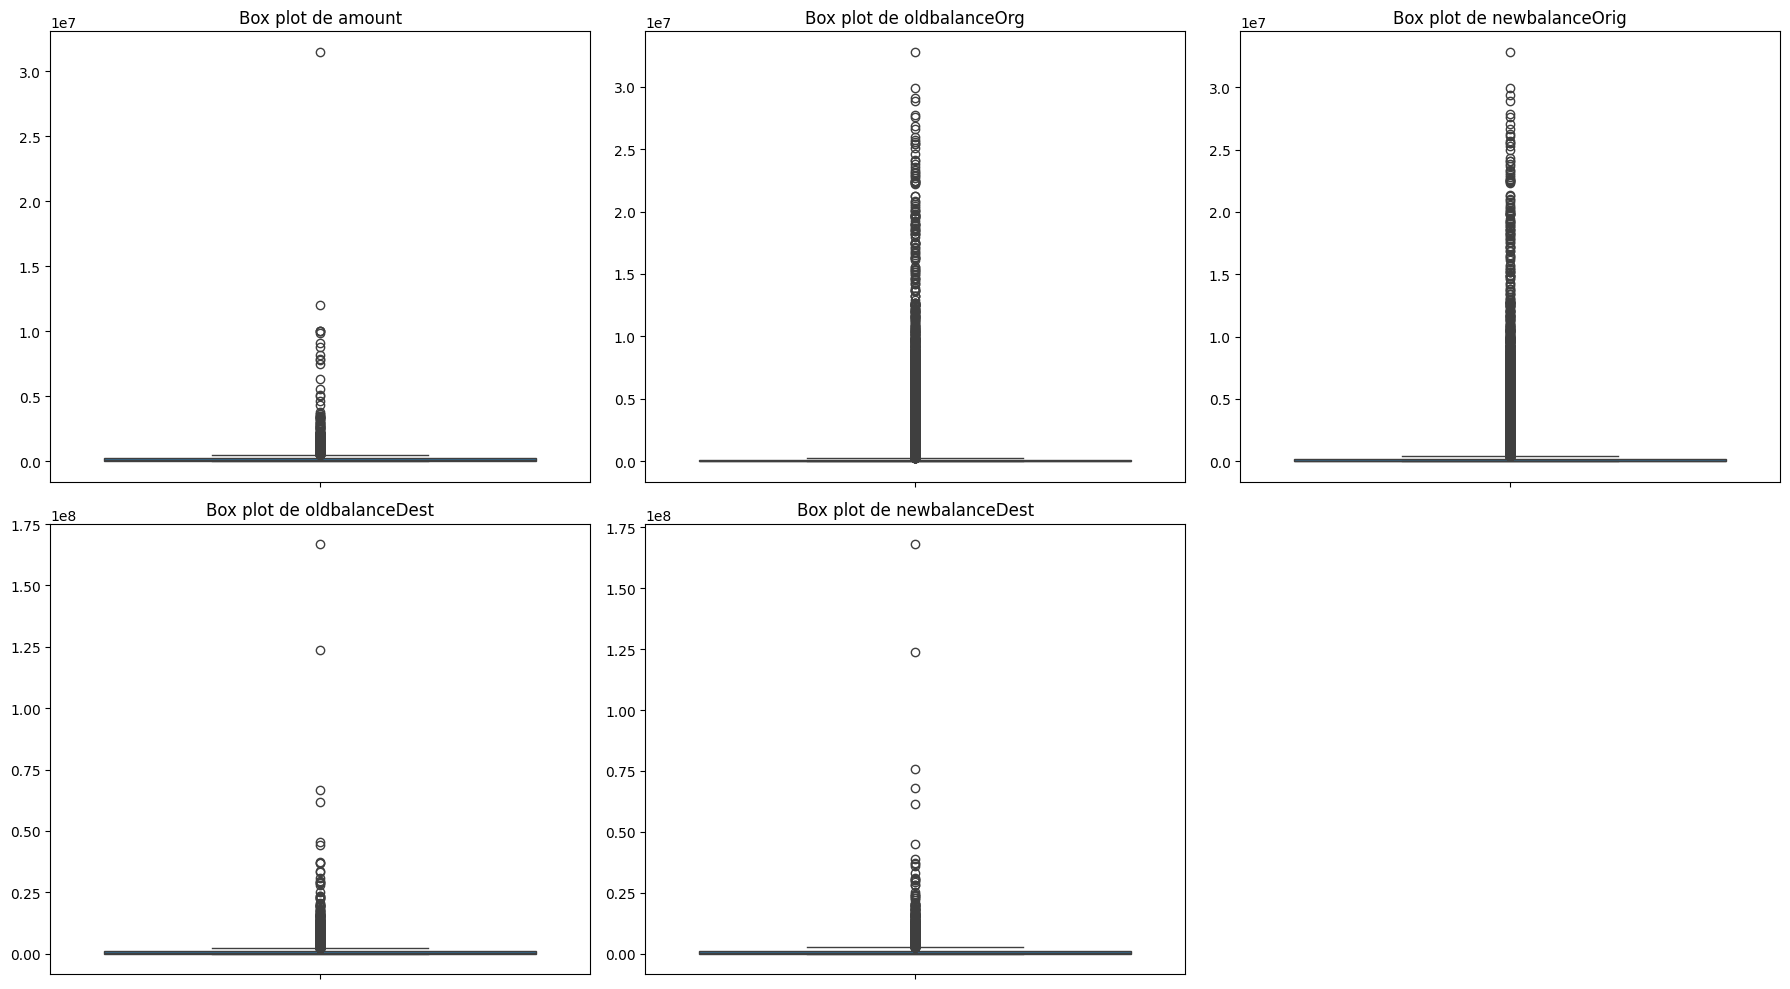


Nota: El porcentaje de outliers es de (30.72%).


In [ ]:
# Definimos explícitamente las columnas numéricas para el análisis de outliers ---
# Usamos la lista específica de columnas
numerical_cols_for_outliers = [
    'amount',
    'oldbalanceOrg',
    'newbalanceOrig',
    'oldbalanceDest',
    'newbalanceDest'
]

print(f"\nColumnas numéricas seleccionadas para el análisis de outliers: {numerical_cols_for_outliers}")


# Esto es crucial para el cálculo de cuartiles. 'errors='coerce'' convertirá valores no numéricos a NaN.
for col in numerical_cols_for_outliers:
    df_CC_Desbalanceado[col] = pd.to_numeric(df_CC_Desbalanceado[col], errors='coerce')

# Es buena práctica eliminar filas con NaN si aparecieron por el 'coerce'
# Se hace solo en las columnas que estamos analizando
df_CC_Desbalanceado.dropna(subset=numerical_cols_for_outliers, inplace=True)
print(f"Shape después de asegurar tipos numéricos manejar NaNs: {df_CC_Desbalanceado.shape}")


# Función para detectar outliers usando IQR
def find_outliers_iqr(df, col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identificar índices de los outliers en esta columna
    outlier_indices = df[(df[col] < lower_bound) | (df[col] > upper_bound)].index
    return outlier_indices, lower_bound, upper_bound

# Calcular y mostrar la cantidad total de outliers
total_records = len(df_CC_Desbalanceado)
all_outliers_indices = set() # Usaremos un set para almacenar índices únicos de filas con outliers

print("\n--- Análisis de Outliers por Columna (Método IQR) ---")
for col in numerical_cols_for_outliers:
    outlier_indices_col, lb, ub = find_outliers_iqr(df_CC_Desbalanceado, col)
    num_outliers_col = len(outlier_indices_col)

    if num_outliers_col > 0:
        print(f"Columna '{col}': {num_outliers_col} outliers detectados. (Rango aceptable: [{lb:.2f}, {ub:.2f}])")
        all_outliers_indices.update(outlier_indices_col.tolist()) # Añadir los índices de las filas con outliers

# Contar el número de filas únicas que contienen al menos un outlier
num_unique_rows_with_outlier = len(all_outliers_indices)
percentage_outliers_total_rows = (num_unique_rows_with_outlier / total_records) * 100

print(f"\n--- Resumen General de Outliers ---")
print(f"Número total de registros en el dataset: {total_records}")
print(f"Número de registros con al menos un outlier (según IQR en columnas numéricas): {num_unique_rows_with_outlier}")
print(f"Porcentaje de registros con al menos un outlier: {percentage_outliers_total_rows:.2f}%")

# --- Visualización (Box plots para las columnas con outliers) ---
print("\n--- Visualización de Box Plots (para columnas con outliers) ---")
# Ajustar el tamaño de la figura y el número de subplots dinámicamente
num_plots = len(numerical_cols_for_outliers)
if num_plots > 0:
    cols_per_row = 3
    rows = (num_plots + cols_per_row - 1) // cols_per_row
    plt.figure(figsize=(cols_per_row * 6, rows * 5))

    for i, col in enumerate(numerical_cols_for_outliers):
        plt.subplot(rows, cols_per_row, i + 1)
        sns.boxplot(y=df_CC_Desbalanceado[col])
        plt.title(f'Box plot de {col}')
        plt.ylabel('')
    plt.tight_layout()
    plt.show()


print(f"\nNota: El porcentaje de outliers es de ({percentage_outliers_total_rows:.2f}%).")

In [ ]:
df_CC_NO_ED_Desbalanceado_Con_Outliers = df_CC_Desbalanceado.copy()
df_CC_NO_ED_Desbalanceado_Con_Outliers = df_CC_NO_ED_Desbalanceado_Con_Outliers.drop(columns=['isFraud'])

In [ ]:
df_CC_NO_ED_Desbalanceado_Con_Outliers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8015 entries, 0 to 8014
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   amount                    8015 non-null   float64
 1   oldbalanceOrg             8015 non-null   float64
 2   newbalanceOrig            8015 non-null   float64
 3   oldbalanceDest            8015 non-null   float64
 4   newbalanceDest            8015 non-null   float64
 5   fraud_category_5_classes  8015 non-null   object 
 6   type_CASH_IN              8015 non-null   int64  
 7   type_CASH_OUT             8015 non-null   int64  
 8   type_DEBIT                8015 non-null   int64  
 9   type_PAYMENT              8015 non-null   int64  
 10  type_TRANSFER             8015 non-null   int64  
dtypes: float64(5), int64(5), object(1)
memory usage: 688.9+ KB



Columnas numéricas seleccionadas para el análisis y limpieza de outliers: ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']

Identificando outliers en cada columna...
Columna 'amount': 392 outliers identificados.
Columna 'oldbalanceOrg': 1405 outliers identificados.
Columna 'newbalanceOrig': 1319 outliers identificados.
Columna 'oldbalanceDest': 983 outliers identificados.
Columna 'newbalanceDest': 932 outliers identificados.

Número total de registros antes de eliminar outliers: 8015
Número de registros con al menos un outlier identificado: 2462
Porcentaje de registros con al menos un outlier identificado: 30.72%

Limpieza de outliers completada (filas eliminadas).
Información del DataFrame después de la limpieza de outliers:
<class 'pandas.core.frame.DataFrame'>
Index: 5553 entries, 1 to 8013
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   amount       

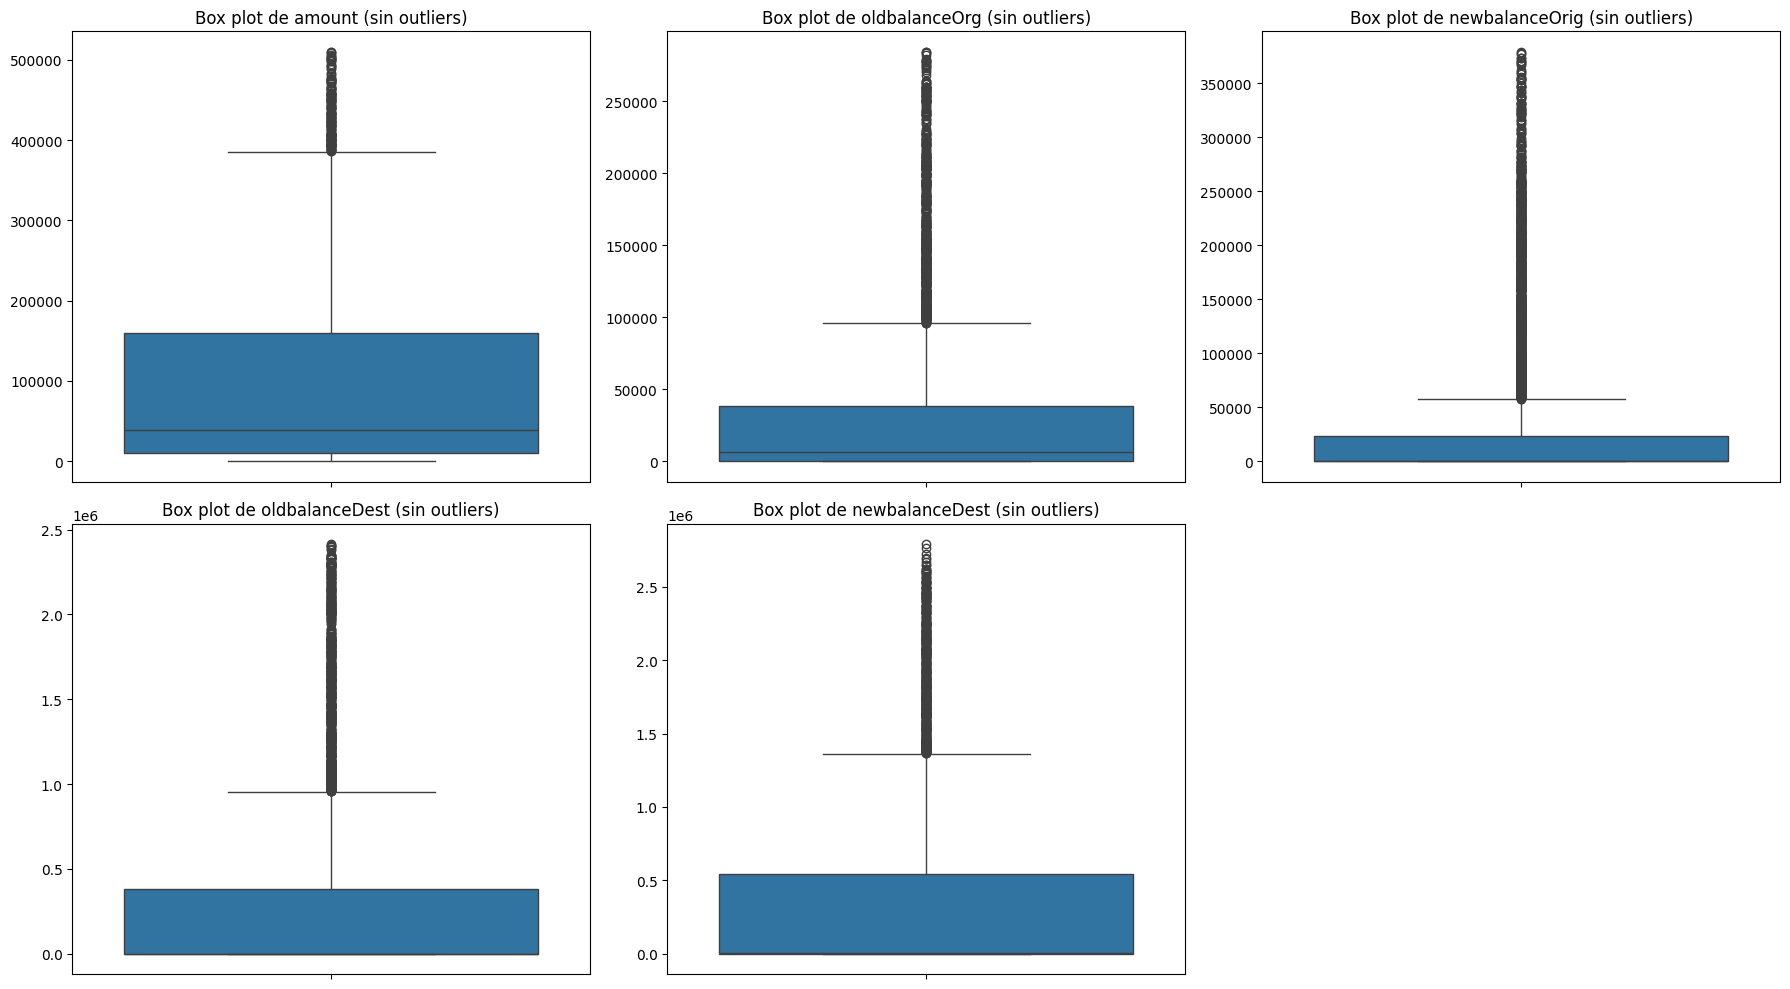

In [ ]:
# Eliminación de los Outliers

df_CC_NO_ED_Desbalanceado_Sin_Outlier = df_CC_NO_ED_Desbalanceado_Con_Outliers.copy()

# 1. Definir las columnas numéricas relevantes para el análisis de outliers
numerical_cols_for_outliers = [
    'amount',
    'oldbalanceOrg',
    'newbalanceOrig',
    'oldbalanceDest',
    'newbalanceDest'
]

print(f"\nColumnas numéricas seleccionadas para el análisis y limpieza de outliers: {numerical_cols_for_outliers}")

# 2. Función para identificar los índices de outliers usando IQR
def get_outlier_indices_iqr(df, col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Devuelve los índices de las filas que son outliers en esta columna
    return df[(df[col] < lower_bound) | (df[col] > upper_bound)].index

# 3. Recopilar todos los índices de filas que contienen al menos un outlier
all_outlier_indices_to_drop = set() # Usamos un set para asegurar la unicidad de los índices

print("\nIdentificando outliers en cada columna...")
for col in numerical_cols_for_outliers:
    outlier_indices_col = get_outlier_indices_iqr(df_CC_NO_ED_Desbalanceado_Sin_Outlier, col)
    num_outliers_col = len(outlier_indices_col)

    if num_outliers_col > 0:
        print(f"Columna '{col}': {num_outliers_col} outliers identificados.")
        all_outlier_indices_to_drop.update(outlier_indices_col.tolist()) # Añadir los índices

num_rows_before = len(df_CC_NO_ED_Desbalanceado_Sin_Outlier)
num_outliers_identified = len(all_outlier_indices_to_drop)
percentage_outliers_identified = (num_outliers_identified / num_rows_before) * 100

print(f"\nNúmero total de registros antes de eliminar outliers: {num_rows_before}")
print(f"Número de registros con al menos un outlier identificado: {num_outliers_identified}")
print(f"Porcentaje de registros con al menos un outlier identificado: {percentage_outliers_identified:.2f}%")

# 4. Eliminar las filas identificadas como outliers
# Usamos .copy() al final para asegurar que el nuevo DataFrame es independiente
df_CC_NO_ED_Desbalanceado_Sin_Outlier = df_CC_NO_ED_Desbalanceado_Sin_Outlier.drop(
    index=list(all_outlier_indices_to_drop)
).copy()

print("\nLimpieza de outliers completada (filas eliminadas).")
print("Información del DataFrame después de la limpieza de outliers:")
df_CC_NO_ED_Desbalanceado_Sin_Outlier.info()
print(f"Número de registros después de eliminar outliers: {len(df_CC_NO_ED_Desbalanceado_Sin_Outlier)}")

#  Visualización para confirmar la eliminación de outliers
print("\n--- Visualización de Box Plots (después de eliminar outliers) ---")

num_plots = len(numerical_cols_for_outliers)
if num_plots > 0:
    cols_per_row = 3
    rows = (num_plots + cols_per_row - 1) // cols_per_row
    plt.figure(figsize=(cols_per_row * 6, rows * 5))

    for i, col in enumerate(numerical_cols_for_outliers):
        plt.subplot(rows, cols_per_row, i + 1)
        sns.boxplot(y=df_CC_NO_ED_Desbalanceado_Sin_Outlier[col])
        plt.title(f'Box plot de {col} (sin outliers)')
        plt.ylabel('')
    plt.tight_layout()
    plt.show()
else:
    print("No hay columnas numéricas para graficar Box Plots.")


In [ ]:
df_CC_NO_ED_Desbalanceado_Sin_Outlier.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5553 entries, 1 to 8013
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   amount                    5553 non-null   float64
 1   oldbalanceOrg             5553 non-null   float64
 2   newbalanceOrig            5553 non-null   float64
 3   oldbalanceDest            5553 non-null   float64
 4   newbalanceDest            5553 non-null   float64
 5   fraud_category_5_classes  5553 non-null   object 
 6   type_CASH_IN              5553 non-null   int64  
 7   type_CASH_OUT             5553 non-null   int64  
 8   type_DEBIT                5553 non-null   int64  
 9   type_PAYMENT              5553 non-null   int64  
 10  type_TRANSFER             5553 non-null   int64  
dtypes: float64(5), int64(5), object(1)
memory usage: 520.6+ KB


## Escalado de Datos

In [ ]:
# Data frame con el que vamos a trabajar y tendría CC, ED, está desbalanceado y con Outliers:
df_CC_SI_ED_Desbalanceado_Con_Outliers = df_CC_NO_ED_Desbalanceado_Con_Outliers.copy()

In [ ]:
df_CC_SI_ED_Desbalanceado_Con_Outliers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8015 entries, 0 to 8014
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   amount                    8015 non-null   float64
 1   oldbalanceOrg             8015 non-null   float64
 2   newbalanceOrig            8015 non-null   float64
 3   oldbalanceDest            8015 non-null   float64
 4   newbalanceDest            8015 non-null   float64
 5   fraud_category_5_classes  8015 non-null   object 
 6   type_CASH_IN              8015 non-null   int64  
 7   type_CASH_OUT             8015 non-null   int64  
 8   type_DEBIT                8015 non-null   int64  
 9   type_PAYMENT              8015 non-null   int64  
 10  type_TRANSFER             8015 non-null   int64  
dtypes: float64(5), int64(5), object(1)
memory usage: 688.9+ KB


In [ ]:
# tenemos las siguientes columnas:
# amount, oldbalanceOrg, newbalanceOrig, oldbalanceDest, newbalanceDest (numéricas continuas)
# fraud_category_5_classes (variable objetivo, no se escala)
# type_CASH_IN, type_CASH_OUT, type_DEBIT, type_PAYMENT, type_TRANSFER (One-Hot Encoded, no se escalan)


# 1. Identificar las columnas numéricas para escalar
# Basado en el `info()` , seleccionamos las 5 primeras.
numerical_cols_to_scale = [
    'amount',
    'oldbalanceOrg',
    'newbalanceOrig',
    'oldbalanceDest',
    'newbalanceDest'
]

print(f"\nColumnas numéricas identificadas para el escalado: {numerical_cols_to_scale}")

# 2. Instanciar el escalador
scaler = StandardScaler()

# 3. Aplicar el escalado solo a las columnas numéricas seleccionadas
# fit_transform calcula la media y desviación estándar y luego aplica la transformación
df_CC_SI_ED_Desbalanceado_Con_Outliers[numerical_cols_to_scale] = scaler.fit_transform(
    df_CC_SI_ED_Desbalanceado_Con_Outliers[numerical_cols_to_scale]
)

print("\nEscalado de datos completado.")
print("Primeras 5 filas del DataFrame df_CC_SI_ED_Desbalanceado_Con_Outliers después del escalado:")
print(df_CC_SI_ED_Desbalanceado_Con_Outliers.head())

print("\nInformación del DataFrame df_CC_SI_ED_Desbalanceado_Con_Outliers después del escalado:")
df_CC_SI_ED_Desbalanceado_Con_Outliers.info()




Columnas numéricas identificadas para el escalado: ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']

Escalado de datos completado.
Primeras 5 filas del DataFrame df_CC_SI_ED_Desbalanceado_Con_Outliers después del escalado:
     amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  newbalanceDest  \
0 -0.243403       0.758673        0.757667       -0.260965       -0.291466   
1 -0.194790      -0.292631       -0.296479       -0.283899       -0.284148   
2  0.238642      -0.292631       -0.296479        2.211477        2.161676   
3 -0.154310      -0.292631       -0.296479       -0.261623       -0.256710   
4 -0.086812      -0.283212       -0.296479       -0.223547       -0.210069   

  fraud_category_5_classes  type_CASH_IN  type_CASH_OUT  type_DEBIT  \
0                 Legitima             1              0           0   
1                 Legitima             0              1           0   
2                 Legitima             0              1      


Columnas numéricas seleccionadas para el análisis y limpieza de outliers: ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']

Identificando outliers en cada columna...
Columna 'amount': 392 outliers identificados.
Columna 'oldbalanceOrg': 1405 outliers identificados.
Columna 'newbalanceOrig': 1319 outliers identificados.
Columna 'oldbalanceDest': 983 outliers identificados.
Columna 'newbalanceDest': 932 outliers identificados.

Número total de registros antes de eliminar outliers: 8015
Número de registros con al menos un outlier identificado: 2462
Porcentaje de registros con al menos un outlier identificado: 30.72%

Limpieza de outliers completada (filas eliminadas).
Información del DataFrame después de la limpieza de outliers:
<class 'pandas.core.frame.DataFrame'>
Index: 5553 entries, 1 to 8013
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   amount       

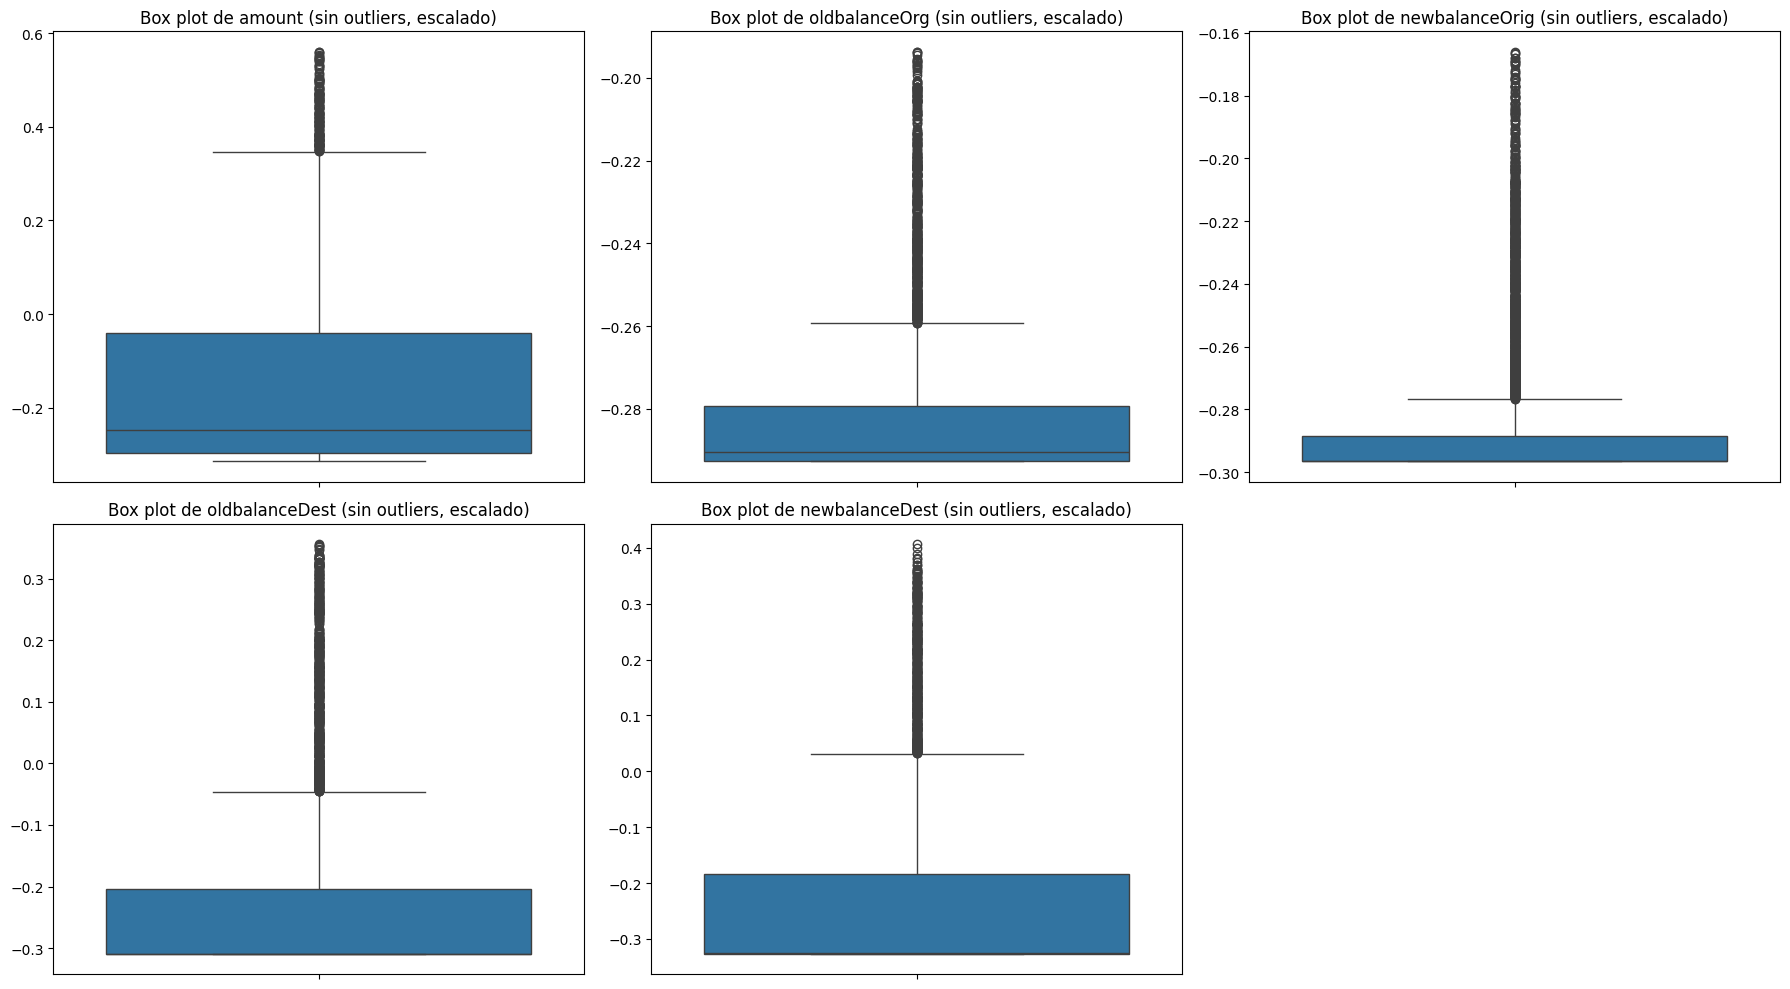

In [ ]:
# Creamos el Dataset con Escalado de datos, sin outliers, desbalanceado y con CC:

# Para ello, solo faltaría eliminar los outliers:

df_CC_SI_ED_Desbalanceado_Sin_Outliers = df_CC_SI_ED_Desbalanceado_Con_Outliers.copy()


# Definir las columnas numéricas relevantes para el análisis de outliers
# Estas son las mismas 5 columnas que ya identificamos para el análisis de outliers
# y que previamente fueron escaladas.
numerical_cols_for_outliers = [
    'amount',
    'oldbalanceOrg',
    'newbalanceOrig',
    'oldbalanceDest',
    'newbalanceDest'
]

print(f"\nColumnas numéricas seleccionadas para el análisis y limpieza de outliers: {numerical_cols_for_outliers}")

# 2. Función para identificar los índices de outliers usando IQR
# Esta función es la misma, pero la aplicamos a los datos ya escalados.

def get_outlier_indices_iqr(df, col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Devuelve los índices de las filas que son outliers en esta columna
    return df[(df[col] < lower_bound) | (df[col] > upper_bound)].index

# 3. Recopilar todos los índices de filas que contienen al menos un outlier
all_outlier_indices_to_drop = set() # Usamos un set para asegurar la unicidad de los índices

print("\nIdentificando outliers en cada columna...")
for col in numerical_cols_for_outliers:
    outlier_indices_col = get_outlier_indices_iqr(df_CC_SI_ED_Desbalanceado_Sin_Outliers, col)
    num_outliers_col = len(outlier_indices_col)

    if num_outliers_col > 0:
        print(f"Columna '{col}': {num_outliers_col} outliers identificados.")
        all_outlier_indices_to_drop.update(outlier_indices_col.tolist()) # Añadir los índices

num_rows_before = len(df_CC_SI_ED_Desbalanceado_Sin_Outliers)
num_outliers_identified = len(all_outlier_indices_to_drop)
percentage_outliers_identified = (num_outliers_identified / num_rows_before) * 100

print(f"\nNúmero total de registros antes de eliminar outliers: {num_rows_before}")
print(f"Número de registros con al menos un outlier identificado: {num_outliers_identified}")
print(f"Porcentaje de registros con al menos un outlier identificado: {percentage_outliers_identified:.2f}%")

# 4. Eliminar las filas identificadas como outliers
# Usamos .copy() al final para asegurar que el nuevo DataFrame es independiente
df_CC_SI_ED_Desbalanceado_Sin_Outliers = df_CC_SI_ED_Desbalanceado_Sin_Outliers.drop(
    index=list(all_outlier_indices_to_drop)
).copy()

print("\nLimpieza de outliers completada (filas eliminadas).")
print("Información del DataFrame después de la limpieza de outliers:")
df_CC_SI_ED_Desbalanceado_Sin_Outliers.info()
print(f"Número de registros después de eliminar outliers: {len(df_CC_SI_ED_Desbalanceado_Sin_Outliers)}")

# Visualización para confirmar la eliminación de outliers
print("\n--- Visualización de Box Plots (después de eliminar outliers) ---")
num_plots = len(numerical_cols_for_outliers)
if num_plots > 0:
    cols_per_row = 3
    rows = (num_plots + cols_per_row - 1) // cols_per_row
    plt.figure(figsize=(cols_per_row * 6, rows * 5))

    for i, col in enumerate(numerical_cols_for_outliers):
        plt.subplot(rows, cols_per_row, i + 1)
        sns.boxplot(y=df_CC_SI_ED_Desbalanceado_Sin_Outliers[col])
        plt.title(f'Box plot de {col} (sin outliers, escalado)')
        plt.ylabel('')
    plt.tight_layout()
    plt.show()
else:
    print("No hay columnas numéricas para graficar Box Plots.")

In [ ]:
df_CC_SI_ED_Desbalanceado_Sin_Outliers.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5553 entries, 1 to 8013
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   amount                    5553 non-null   float64
 1   oldbalanceOrg             5553 non-null   float64
 2   newbalanceOrig            5553 non-null   float64
 3   oldbalanceDest            5553 non-null   float64
 4   newbalanceDest            5553 non-null   float64
 5   fraud_category_5_classes  5553 non-null   object 
 6   type_CASH_IN              5553 non-null   int64  
 7   type_CASH_OUT             5553 non-null   int64  
 8   type_DEBIT                5553 non-null   int64  
 9   type_PAYMENT              5553 non-null   int64  
 10  type_TRANSFER             5553 non-null   int64  
dtypes: float64(5), int64(5), object(1)
memory usage: 520.6+ KB


In [ ]:
#Guardamos el dataset en el drive para futuros usos:
from google.colab import drive
drive.mount('/content/drive')

# Ruta en Google Drive para guardar el archivo
drive_folder_path = '/content/drive/Shareddrives/Introducción a IA/Trabajo Práctico 2/8k/Datos_Supervisado'

output_csv_name_drive = 'df_CC_NO_ED_Desbalanceado_Con_Outliers.csv'
full_output_path_drive = os.path.join(drive_folder_path, output_csv_name_drive)

df_CC_NO_ED_Desbalanceado_Con_Outliers.to_csv(full_output_path_drive, index=False)
print(f"Dataset df_CC_NO_ED_Desbalanceado_Con_Outliers guardado en Google Drive: '{full_output_path_drive}'")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset df_CC_NO_ED_Desbalanceado_Con_Outliers guardado en Google Drive: '/content/drive/Shareddrives/Introducción a IA/Trabajo Práctico 2/8k/Datos_Supervisado/df_CC_NO_ED_Desbalanceado_Con_Outliers.csv'


In [ ]:
#Guardamos el dataset en el drive para futuros usos:
from google.colab import drive
drive.mount('/content/drive')

# Ruta en Google Drive para guardar el archivo
drive_folder_path = '/content/drive/Shareddrives/Introducción a IA/Trabajo Práctico 2/8k/Datos_Supervisado'

output_csv_name_drive = 'df_CC_SI_ED_Desbalanceado_Sin_Outliers.csv'
full_output_path_drive = os.path.join(drive_folder_path, output_csv_name_drive)

df_CC_SI_ED_Desbalanceado_Sin_Outliers.to_csv(full_output_path_drive, index=False)
print(f"Dataset df_CC_SI_ED_Desbalanceado_Sin_Outliers guardado en Google Drive: '{full_output_path_drive}'")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset df_CC_SI_ED_Desbalanceado_Sin_Outliers guardado en Google Drive: '/content/drive/Shareddrives/Introducción a IA/Trabajo Práctico 2/8k/Datos_Supervisado/df_CC_SI_ED_Desbalanceado_Sin_Outliers.csv'


## Balanceo de Clases

Nuestro dataset tiene un desbalance muy marcado, esto debido a que los casos de fraudes ocurren mucho menos que los casos legítimos. En este dataset, contamos con 99.8709% de casos legítimos y 0.01291% de casos de fraude, por lo tanto, si queremos balancear las 5 clases, tendríamos que generar una cantidad muy grande de datos sintéticos que el modelo podría memorizar, se decidió aumentar la cantidad de datos en un total de 1200 por clase y luego realizaremos un submuestreo a la clase mayoritaria para dejarla en 1200.


In [ ]:
# Creamos la copia específica para este caso de balanceo TOTAL (SMOTE + Undersampling)
# Data set que vamos a balancear
# Vamos a crear df_CC_NO_ED_Balanceado_Con_Outliers
df_CC_NO_ED_Desbalanceado_Con_Outliers = pd.read_csv('/content/drive/Shareddrives/Introducción a IA/Trabajo Práctico 2/8k/Datos_Supervisado/df_CC_NO_ED_Desbalanceado_Con_Outliers.csv')
df_CC_NO_ED_Balanceado_Con_Outliers = df_CC_NO_ED_Desbalanceado_Con_Outliers.copy()

# 1. Definir la variable objetivo y las características
TARGET = 'fraud_category_5_classes'
X_full = df_CC_NO_ED_Balanceado_Con_Outliers.drop(columns=[TARGET]).copy() # Todas las características
y_full = df_CC_NO_ED_Balanceado_Con_Outliers[TARGET].copy() # La variable objetivo

print(f"\nShape de X_full antes de balanceo: {X_full.shape}")
print(f"Shape de y_full antes de balanceo: {y_full.shape}")
print(f"Distribución de clases en y_full antes de balanceo:\n{y_full.value_counts()}")

# --- Mapeo de clases a numérico para SMOTE ---
unique_classes_sorted = sorted(y_full.unique())
class_to_int_map = {cls_name: i for i, cls_name in enumerate(unique_classes_sorted)}
int_to_class_map = {i: cls_name for cls_name, i in class_to_int_map.items()}
y_full_numeric = y_full.map(class_to_int_map)

# 2. Aplicar SMOTE a las clases minoritarias
target_samples_per_fraud_class = 1200

# Estrategia para SMOTE: solo las clases de fraude
sampling_strategy_smote = {}
for cls_name in unique_classes_sorted:
    # Only apply SMOTE if the class is not 'Legitima' and has at least 2 samples
    if cls_name != 'Legitima' and y_full.value_counts()[cls_name] >= 2:
        sampling_strategy_smote[class_to_int_map[cls_name]] = target_samples_per_fraud_class

print(f"\nSub-paso: Aplicando SMOTE a las clases de fraude con estrategia: {sampling_strategy_smote}")
# Reduced n_neighbors to handle very small minority classes
smote = SMOTE(sampling_strategy=sampling_strategy_smote, random_state=42, k_neighbors=1)
X_smoted, y_smoted_numeric = smote.fit_resample(X_full, y_full_numeric)

# Volver a mapear las etiquetas de SMOTE a sus nombres originales
y_smoted = y_smoted_numeric.map(int_to_class_map)

print(f"Shape después de SMOTE: {X_smoted.shape}")
print(f"Distribución de clases después de SMOTE:\n{y_smoted.value_counts()}")


# 3. Aplicar submuestreo a la clase 'Legítima' en el conjunto resultante de SMOTE
# Primero, volvemos a juntar X y y en un solo DataFrame para facilitar el submuestreo por clase
df_combined_after_smote = pd.concat([X_smoted, y_smoted], axis=1)

# Separar las clases nuevamente para el submuestreo
df_legitima = df_combined_after_smote[df_combined_after_smote[TARGET] == 'Legitima']
df_fraude_others = df_combined_after_smote[df_combined_after_smote[TARGET] != 'Legitima']

# Submuestrear la clase legítima al mismo tamaño que las clases de fraude
n_samples_legitima = target_samples_per_fraud_class # Queremos 20,000 ejemplos de legítimas también

print(f"\nSub-paso: Submuestreando la clase 'Legítima' a {n_samples_legitima} ejemplos.")
df_legitima_undersampled = resample(df_legitima,
                                    replace=False,    # Sin reemplazo para evitar duplicados exactos
                                    n_samples=n_samples_legitima, # Número de muestras a obtener
                                    random_state=42)  # Para resultados reproducibles

# 4. Concatenar todas las partes balanceadas
df_balanceado_combinado_FINAL = pd.concat([df_legitima_undersampled, df_fraude_others])

# Mezclar el DataFrame final para que las clases no estén agrupadas
df_balanceado_combinado_FINAL = df_balanceado_combinado_FINAL.sample(frac=1, random_state=42).reset_index(drop=True)


# 5. Verificar el resultado final del balanceo
print(f"\nShape final del DataFrame balanceado (SMOTE + Undersampling): {df_balanceado_combinado_FINAL.shape}")
print(f"Distribución de clases en el DataFrame balanceado final:\n{df_balanceado_combinado_FINAL[TARGET].value_counts()}")
print(f"Distribución NORMALIZADA de clases en el DataFrame balanceado final:\n{df_balanceado_combinado_FINAL[TARGET].value_counts(normalize=True)}")

# El DataFrame final para este caso de balanceo total es:
df_CC_NO_ED_Balanceado_Con_Outliers = df_balanceado_combinado_FINAL.copy()

print("\nBalanceo de clases (SMOTE + Undersampling) completado para el DataFrame COMPLETO.")
print("Ahora, df_CC_NO_ED_Balanceado_Con_Outliers es el DataFrame balanceado completo.")


Shape de X_full antes de balanceo: (8015, 10)
Shape de y_full antes de balanceo: (8015,)
Distribución de clases en y_full antes de balanceo:
fraud_category_5_classes
Legitima                                   7989
Fraude - Retiro (Cash Out) - Alto Monto      10
Fraude - Transferencia - Alto Monto           7
Fraude - Retiro (Cash Out) - Bajo Monto       5
Fraude - Transferencia - Bajo Monto           4
Name: count, dtype: int64

Sub-paso: Aplicando SMOTE a las clases de fraude con estrategia: {0: 1200, 1: 1200, 2: 1200, 3: 1200}
Shape después de SMOTE: (12789, 10)
Distribución de clases después de SMOTE:
fraud_category_5_classes
Legitima                                   7989
Fraude - Transferencia - Alto Monto        1200
Fraude - Transferencia - Bajo Monto        1200
Fraude - Retiro (Cash Out) - Alto Monto    1200
Fraude - Retiro (Cash Out) - Bajo Monto    1200
Name: count, dtype: int64

Sub-paso: Submuestreando la clase 'Legítima' a 1200 ejemplos.

Shape final del DataFrame balanc

In [ ]:
#Guardamos el dataset en el drive para futuros usos:
from google.colab import drive
drive.mount('/content/drive')

# Ruta en Google Drive para guardar el archivo
drive_folder_path = '/content/drive/Shareddrives/Introducción a IA/Trabajo Práctico 2/8k/Datos_Supervisado'

output_csv_name_drive = 'df_CC_NO_ED_Balanceado_Con_Outliers.csv'
full_output_path_drive = os.path.join(drive_folder_path, output_csv_name_drive)

df_CC_NO_ED_Balanceado_Con_Outliers.to_csv(full_output_path_drive, index=False)
print(f"Dataset df_CC_NO_ED_Balanceado_Con_Outliers guardado en Google Drive: '{full_output_path_drive}'")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset df_CC_NO_ED_Balanceado_Con_Outliers guardado en Google Drive: '/content/drive/Shareddrives/Introducción a IA/Trabajo Práctico 2/8k/Datos_Supervisado/df_CC_NO_ED_Balanceado_Con_Outliers.csv'


In [ ]:
# Vamos a crear df_CC_NO_ED_Balanceado_Sin_Outliers
df_CC_NO_ED_Desbalanceado_Sin_Outlier = pd.read_csv('/content/drive/Shareddrives/Introducción a IA/Trabajo Práctico 2/8k/Datos_Supervisado/df_CC_NO_ED_Desbalanceado_Sin_Outlier.csv')
df_CC_NO_ED_Balanceado_Sin_Outliers = df_CC_NO_ED_Desbalanceado_Sin_Outlier.copy()


# 1. Definir la variable objetivo y las características
TARGET = 'fraud_category_5_classes'
X_full = df_CC_NO_ED_Balanceado_Sin_Outliers.drop(columns=[TARGET]).copy() # Todas las características
y_full = df_CC_NO_ED_Balanceado_Sin_Outliers[TARGET].copy() # La variable objetivo

print(f"\nShape de X_full antes de balanceo: {X_full.shape}")
print(f"Shape de y_full antes de balanceo: {y_full.shape}")
print(f"Distribución de clases en y_full antes de balanceo:\n{y_full.value_counts()}")

# --- Mapeo de clases a numérico para SMOTE ---
unique_classes_sorted = sorted(y_full.unique())
class_to_int_map = {cls_name: i for i, cls_name in enumerate(unique_classes_sorted)}
int_to_class_map = {i: cls_name for cls_name, i in class_to_int_map.items()}
y_full_numeric = y_full.map(class_to_int_map)

# 2. Aplicar SMOTE a las clases minoritarias
target_samples_per_fraud_class = 1200

# Estrategia para SMOTE: solo las clases de fraude
sampling_strategy_smote = {}
for cls_name in unique_classes_sorted:
    # Only apply SMOTE if the class is not 'Legitima' and has at least 2 samples
    if cls_name != 'Legitima' and y_full.value_counts()[cls_name] >= 2:
        sampling_strategy_smote[class_to_int_map[cls_name]] = target_samples_per_fraud_class


print(f"\nSub-paso: Aplicando SMOTE a las clases de fraude con estrategia: {sampling_strategy_smote}")
smote = SMOTE(sampling_strategy=sampling_strategy_smote, random_state=42, k_neighbors=1)
X_smoted, y_smoted_numeric = smote.fit_resample(X_full, y_full_numeric)

# Volver a mapear las etiquetas de SMOTE a sus nombres originales
y_smoted = y_smoted_numeric.map(int_to_class_map)

print(f"Shape después de SMOTE: {X_smoted.shape}")
print(f"Distribución de clases después de SMOTE:\n{y_smoted.value_counts()}")


# 3. Aplicar submuestreo a la clase 'Legítima' en el conjunto resultante de SMOTE
# Primero, volvemos a juntar X y y en un solo DataFrame para facilitar el submuestreo por clase
df_combined_after_smote = pd.concat([X_smoted, y_smoted], axis=1)

# Separar las clases nuevamente para el submuestreo
df_legitima = df_combined_after_smote[df_combined_after_smote[TARGET] == 'Legitima']
df_fraude_others = df_combined_after_smote[df_combined_after_smote[TARGET] != 'Legitima']

# Submuestrear la clase legítima al mismo tamaño que las clases de fraude
n_samples_legitima = target_samples_per_fraud_class # Queremos 20,000 ejemplos de legítimas también

print(f"\nSub-paso: Submuestreando la clase 'Legítima' a {n_samples_legitima} ejemplos.")
df_legitima_undersampled = resample(df_legitima,
                                    replace=False,    # Sin reemplazo para evitar duplicados exactos
                                    n_samples=n_samples_legitima, # Número de muestras a obtener
                                    random_state=42)  # Para resultados reproducibles

# 4. Concatenar todas las partes balanceadas
df_balanceado_combinado_FINAL = pd.concat([df_legitima_undersampled, df_fraude_others])

# Mezclar el DataFrame final para que las clases no estén agrupadas
df_balanceado_combinado_FINAL = df_balanceado_combinado_FINAL.sample(frac=1, random_state=42).reset_index(drop=True)

df_CC_NO_ED_Balanceado_Sin_Outliers = df_balanceado_combinado_FINAL.copy()
# 5. Verificar el resultado final del balanceo
print(f"\nShape final del DataFrame balanceado (SMOTE + Undersampling): {df_CC_NO_ED_Balanceado_Sin_Outliers.shape}")
print(f"Distribución de clases en el DataFrame balanceado final:\n{df_CC_NO_ED_Balanceado_Sin_Outliers[TARGET].value_counts()}")
print(f"Distribución NORMALIZADA de clases en el DataFrame balanceado final:\n{df_CC_NO_ED_Balanceado_Sin_Outliers[TARGET].value_counts(normalize=True)}")


print("\nBalanceo de clases (SMOTE + Undersampling) completado para el DataFrame COMPLETO.")
print("Ahora, df_CC_NO_ED_Balanceado_Sin_Outliers_FINAL_COMBINED es el DataFrame balanceado completo.")


Shape de X_full antes de balanceo: (5553, 10)
Shape de y_full antes de balanceo: (5553,)
Distribución de clases en y_full antes de balanceo:
fraud_category_5_classes
Legitima                                   5541
Fraude - Transferencia - Bajo Monto           4
Fraude - Transferencia - Alto Monto           3
Fraude - Retiro (Cash Out) - Alto Monto       3
Fraude - Retiro (Cash Out) - Bajo Monto       2
Name: count, dtype: int64

Sub-paso: Aplicando SMOTE a las clases de fraude con estrategia: {0: 1200, 1: 1200, 2: 1200, 3: 1200}
Shape después de SMOTE: (10341, 10)
Distribución de clases después de SMOTE:
fraud_category_5_classes
Legitima                                   5541
Fraude - Transferencia - Bajo Monto        1200
Fraude - Transferencia - Alto Monto        1200
Fraude - Retiro (Cash Out) - Alto Monto    1200
Fraude - Retiro (Cash Out) - Bajo Monto    1200
Name: count, dtype: int64

Sub-paso: Submuestreando la clase 'Legítima' a 1200 ejemplos.

Shape final del DataFrame balanc

In [ ]:
#Guardamos el dataset en el drive para futuros usos:
from google.colab import drive
drive.mount('/content/drive')

# Ruta en Google Drive para guardar el archivo
drive_folder_path = '/content/drive/Shareddrives/Introducción a IA/Trabajo Práctico 2/8k/Datos_Supervisado'

output_csv_name_drive = 'df_CC_SI_ED_Desbalanceado_Sin_Outliers.csv'
full_output_path_drive = os.path.join(drive_folder_path, output_csv_name_drive)

df_CC_SI_ED_Desbalanceado_Sin_Outliers.to_csv(full_output_path_drive, index=False)
print(f"Dataset df_CC_SI_ED_Desbalanceado_Sin_Outliers guardado en Google Drive: '{full_output_path_drive}'")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset df_CC_SI_ED_Desbalanceado_Sin_Outliers guardado en Google Drive: '/content/drive/Shareddrives/Introducción a IA/Trabajo Práctico 2/8k/Datos_Supervisado/df_CC_SI_ED_Desbalanceado_Sin_Outliers.csv'


In [ ]:
# Crearemos el data set df_CC_SI_ED_Balanceado_Sin_Outliers
df_CC_SI_ED_Desbalanceado_Sin_Outliers = pd.read_csv('/content/drive/Shareddrives/Introducción a IA/Trabajo Práctico 2/8k/Datos_Supervisado/df_CC_SI_ED_Desbalanceado_Sin_Outliers.csv')
df_CC_SI_ED_Balanceado_Sin_Outlier = df_CC_SI_ED_Desbalanceado_Sin_Outliers.copy()
# 1. Definir la variable objetivo y las características
TARGET = 'fraud_category_5_classes'
X_full = df_CC_SI_ED_Balanceado_Sin_Outlier.drop(columns=[TARGET]).copy() # Todas las características
y_full = df_CC_SI_ED_Balanceado_Sin_Outlier[TARGET].copy() # La variable objetivo

print(f"\nShape de X_full antes de balanceo: {X_full.shape}")
print(f"Shape de y_full antes de balanceo: {y_full.shape}")
print(f"Distribución de clases en y_full antes de balanceo:\n{y_full.value_counts()}")

# --- Mapeo de clases a numérico para SMOTE ---
unique_classes_sorted = sorted(y_full.unique())
class_to_int_map = {cls_name: i for i, cls_name in enumerate(unique_classes_sorted)}
int_to_class_map = {i: cls_name for cls_name, i in class_to_int_map.items()}
y_full_numeric = y_full.map(class_to_int_map)

# 2. Aplicar SMOTE a las clases minoritarias
target_samples_per_fraud_class = 1200

# Estrategia para SMOTE: solo las clases de fraude
sampling_strategy_smote = {}
for cls_name in unique_classes_sorted:
    # Only apply SMOTE if the class is not 'Legitima' and has at least 2 samples
    if cls_name != 'Legitima' and y_full.value_counts()[cls_name] >= 2:
        sampling_strategy_smote[class_to_int_map[cls_name]] = target_samples_per_fraud_class


print(f"\nSub-paso: Aplicando SMOTE a las clases de fraude con estrategia: {sampling_strategy_smote}")
smote = SMOTE(sampling_strategy=sampling_strategy_smote, random_state=42, k_neighbors=1)
X_smoted, y_smoted_numeric = smote.fit_resample(X_full, y_full_numeric)

# Volver a mapear las etiquetas de SMOTE a sus nombres originales
y_smoted = y_smoted_numeric.map(int_to_class_map)

print(f"Shape después de SMOTE: {X_smoted.shape}")
print(f"Distribución de clases después de SMOTE:\n{y_smoted.value_counts()}")


# 3. Aplicar submuestreo a la clase 'Legítima' en el conjunto resultante de SMOTE
# Primero, volvemos a juntar X y y en un solo DataFrame para facilitar el submuestreo por clase
df_combined_after_smote = pd.concat([X_smoted, y_smoted], axis=1)

# Separar las clases nuevamente para el submuestreo
df_legitima = df_combined_after_smote[df_combined_after_smote[TARGET] == 'Legitima']
df_fraude_others = df_combined_after_smote[df_combined_after_smote[TARGET] != 'Legitima']

# Submuestrear la clase legítima al mismo tamaño que las clases de fraude
n_samples_legitima = target_samples_per_fraud_class

print(f"\nSub-paso: Submuestreando la clase 'Legítima' a {n_samples_legitima} ejemplos.")
df_legitima_undersampled = resample(df_legitima,
                                    replace=False,    # Sin reemplazo para evitar duplicados exactos
                                    n_samples=n_samples_legitima, # Número de muestras a obtener
                                    random_state=42)  # Para resultados reproducibles

# 4. Concatenar todas las partes balanceadas
df_balanceado_combinado_FINAL = pd.concat([df_legitima_undersampled, df_fraude_others])

# Mezclar el DataFrame final para que las clases no estén agrupadas
df_balanceado_combinado_FINAL = df_balanceado_combinado_FINAL.sample(frac=1, random_state=42).reset_index(drop=True)

df_CC_SI_ED_Balanceado_Sin_Outlier = df_balanceado_combinado_FINAL.copy()
# 5. Verificar el resultado final del balanceo
print(f"\nShape final del DataFrame balanceado (SMOTE + Undersampling): {df_CC_SI_ED_Balanceado_Sin_Outlier.shape}")
print(f"Distribución de clases en el DataFrame balanceado final:\n{df_CC_SI_ED_Balanceado_Sin_Outlier[TARGET].value_counts()}")
print(f"Distribución NORMALIZADA de clases en el DataFrame balanceado final:\n{df_CC_SI_ED_Balanceado_Sin_Outlier[TARGET].value_counts(normalize=True)}")


print("\nBalanceo de clases (SMOTE + Undersampling) completado para el DataFrame COMPLETO.")


Shape de X_full antes de balanceo: (5553, 10)
Shape de y_full antes de balanceo: (5553,)
Distribución de clases en y_full antes de balanceo:
fraud_category_5_classes
Legitima                                   5541
Fraude - Transferencia - Bajo Monto           4
Fraude - Transferencia - Alto Monto           3
Fraude - Retiro (Cash Out) - Alto Monto       3
Fraude - Retiro (Cash Out) - Bajo Monto       2
Name: count, dtype: int64

Sub-paso: Aplicando SMOTE a las clases de fraude con estrategia: {0: 1200, 1: 1200, 2: 1200, 3: 1200}
Shape después de SMOTE: (10341, 10)
Distribución de clases después de SMOTE:
fraud_category_5_classes
Legitima                                   5541
Fraude - Transferencia - Bajo Monto        1200
Fraude - Transferencia - Alto Monto        1200
Fraude - Retiro (Cash Out) - Alto Monto    1200
Fraude - Retiro (Cash Out) - Bajo Monto    1200
Name: count, dtype: int64

Sub-paso: Submuestreando la clase 'Legítima' a 1200 ejemplos.

Shape final del DataFrame balanc

In [ ]:
#Guardamos el dataset en el drive para futuros usos:
from google.colab import drive
drive.mount('/content/drive')

# Ruta en Google Drive para guardar el archivo
drive_folder_path = '/content/drive/Shareddrives/Introducción a IA/Trabajo Práctico 2/8k/Datos_Supervisado'

output_csv_name_drive = 'df_CC_SI_ED_Desbalanceado_Con_Outliers.csv'
full_output_path_drive = os.path.join(drive_folder_path, output_csv_name_drive)

df_CC_SI_ED_Desbalanceado_Con_Outliers.to_csv(full_output_path_drive, index=False)
print(f"Dataset df_CC_SI_ED_Desbalanceado_Con_Outliers guardado en Google Drive: '{full_output_path_drive}'")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset df_CC_SI_ED_Desbalanceado_Con_Outliers guardado en Google Drive: '/content/drive/Shareddrives/Introducción a IA/Trabajo Práctico 2/8k/Datos_Supervisado/df_CC_SI_ED_Desbalanceado_Con_Outliers.csv'


In [ ]:
# Crearemos df_CC_SI_ED_Balanceado_Con_Outliers

df_CC_SI_ED_Desbalanceado_Con_Outliers = pd.read_csv('/content/drive/Shareddrives/Introducción a IA/Trabajo Práctico 2/8k/Datos_Supervisado/df_CC_SI_ED_Desbalanceado_Con_Outliers.csv')
df_CC_SI_ED_Balanceado_Con_Outliers = df_CC_SI_ED_Desbalanceado_Con_Outliers.copy()

# 1. Definir la variable objetivo y las características
TARGET = 'fraud_category_5_classes'
X_full = df_CC_SI_ED_Balanceado_Con_Outliers.drop(columns=[TARGET]).copy() # Todas las características
y_full = df_CC_SI_ED_Balanceado_Con_Outliers[TARGET].copy() # La variable objetivo

print(f"\nShape de X_full antes de balanceo: {X_full.shape}")
print(f"Shape de y_full antes de balanceo: {y_full.shape}")
print(f"Distribución de clases en y_full antes de balanceo:\n{y_full.value_counts()}")

# --- Mapeo de clases a numérico para SMOTE ---
unique_classes_sorted = sorted(y_full.unique())
class_to_int_map = {cls_name: i for i, cls_name in enumerate(unique_classes_sorted)}
int_to_class_map = {i: cls_name for cls_name, i in class_to_int_map.items()}
y_full_numeric = y_full.map(class_to_int_map)

# 2. Aplicar SMOTE a las clases minoritarias
target_samples_per_fraud_class = 1200

# Estrategia para SMOTE: solo las clases de fraude
sampling_strategy_smote = {}
for cls_name in unique_classes_sorted:
    # Only apply SMOTE if the class is not 'Legitima' and has at least 2 samples
    if cls_name != 'Legitima' and y_full.value_counts()[cls_name] >= 2:
        sampling_strategy_smote[class_to_int_map[cls_name]] = target_samples_per_fraud_class


print(f"\nSub-paso: Aplicando SMOTE a las clases de fraude con estrategia: {sampling_strategy_smote}")
smote = SMOTE(sampling_strategy=sampling_strategy_smote, random_state=42, k_neighbors=1)
X_smoted, y_smoted_numeric = smote.fit_resample(X_full, y_full_numeric)

# Volver a mapear las etiquetas de SMOTE a sus nombres originales
y_smoted = y_smoted_numeric.map(int_to_class_map)

print(f"Shape después de SMOTE: {X_smoted.shape}")
print(f"Distribución de clases después de SMOTE:\n{y_smoted.value_counts()}")


# 3. Aplicar submuestreo a la clase 'Legítima' en el conjunto resultante de SMOTE
# Primero, volvemos a juntar X y y en un solo DataFrame para facilitar el submuestreo por clase
df_combined_after_smote = pd.concat([X_smoted, y_smoted], axis=1)

# Separar las clases nuevamente para el submuestreo
df_legitima = df_combined_after_smote[df_combined_after_smote[TARGET] == 'Legitima']
df_fraude_others = df_combined_after_smote[df_combined_after_smote[TARGET] != 'Legitima']

# Submuestrear la clase legítima al mismo tamaño que las clases de fraude
n_samples_legitima = target_samples_per_fraud_class

print(f"\nSub-paso: Submuestreando la clase 'Legítima' a {n_samples_legitima} ejemplos.")
df_legitima_undersampled = resample(df_legitima,
                                    replace=False,    # Sin reemplazo para evitar duplicados exactos
                                    n_samples=n_samples_legitima, # Número de muestras a obtener
                                    random_state=42)  # Para resultados reproducibles

# 4. Concatenar todas las partes balanceadas
df_balanceado_combinado_FINAL = pd.concat([df_legitima_undersampled, df_fraude_others])

# Mezclar el DataFrame final para que las clases no estén agrupadas
df_balanceado_combinado_FINAL = df_balanceado_combinado_FINAL.sample(frac=1, random_state=42).reset_index(drop=True)

df_CC_SI_ED_Balanceado_Con_Outliers = df_balanceado_combinado_FINAL.copy()
# 5. Verificar el resultado final del balanceo
print(f"\nShape final del DataFrame balanceado (SMOTE + Undersampling): {df_CC_SI_ED_Balanceado_Con_Outliers.shape}")
print(f"Distribución de clases en el DataFrame balanceado final:\n{df_CC_SI_ED_Balanceado_Con_Outliers[TARGET].value_counts()}")
print(f"Distribución NORMALIZADA de clases en el DataFrame balanceado final:\n{df_CC_SI_ED_Balanceado_Con_Outliers[TARGET].value_counts(normalize=True)}")


print("\nBalanceo de clases (SMOTE + Undersampling) completado para el DataFrame COMPLETO.")


Shape de X_full antes de balanceo: (8015, 10)
Shape de y_full antes de balanceo: (8015,)
Distribución de clases en y_full antes de balanceo:
fraud_category_5_classes
Legitima                                   7989
Fraude - Retiro (Cash Out) - Alto Monto      10
Fraude - Transferencia - Alto Monto           7
Fraude - Retiro (Cash Out) - Bajo Monto       5
Fraude - Transferencia - Bajo Monto           4
Name: count, dtype: int64

Sub-paso: Aplicando SMOTE a las clases de fraude con estrategia: {0: 1200, 1: 1200, 2: 1200, 3: 1200}
Shape después de SMOTE: (12789, 10)
Distribución de clases después de SMOTE:
fraud_category_5_classes
Legitima                                   7989
Fraude - Transferencia - Alto Monto        1200
Fraude - Transferencia - Bajo Monto        1200
Fraude - Retiro (Cash Out) - Alto Monto    1200
Fraude - Retiro (Cash Out) - Bajo Monto    1200
Name: count, dtype: int64

Sub-paso: Submuestreando la clase 'Legítima' a 1200 ejemplos.

Shape final del DataFrame balanc

## Revisión De Cada Dataset

In [ ]:
df_CC_NO_ED_Desbalanceado_Con_Outliers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8015 entries, 0 to 8014
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   amount                    8015 non-null   float64
 1   oldbalanceOrg             8015 non-null   float64
 2   newbalanceOrig            8015 non-null   float64
 3   oldbalanceDest            8015 non-null   float64
 4   newbalanceDest            8015 non-null   float64
 5   fraud_category_5_classes  8015 non-null   object 
 6   type_CASH_IN              8015 non-null   int64  
 7   type_CASH_OUT             8015 non-null   int64  
 8   type_DEBIT                8015 non-null   int64  
 9   type_PAYMENT              8015 non-null   int64  
 10  type_TRANSFER             8015 non-null   int64  
dtypes: float64(5), int64(5), object(1)
memory usage: 688.9+ KB


In [ ]:
df_CC_NO_ED_Desbalanceado_Sin_Outlier.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5553 entries, 1 to 8013
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   amount                    5553 non-null   float64
 1   oldbalanceOrg             5553 non-null   float64
 2   newbalanceOrig            5553 non-null   float64
 3   oldbalanceDest            5553 non-null   float64
 4   newbalanceDest            5553 non-null   float64
 5   fraud_category_5_classes  5553 non-null   object 
 6   type_CASH_IN              5553 non-null   int64  
 7   type_CASH_OUT             5553 non-null   int64  
 8   type_DEBIT                5553 non-null   int64  
 9   type_PAYMENT              5553 non-null   int64  
 10  type_TRANSFER             5553 non-null   int64  
dtypes: float64(5), int64(5), object(1)
memory usage: 520.6+ KB


In [ ]:
df_CC_SI_ED_Desbalanceado_Con_Outliers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8015 entries, 0 to 8014
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   amount                    8015 non-null   float64
 1   oldbalanceOrg             8015 non-null   float64
 2   newbalanceOrig            8015 non-null   float64
 3   oldbalanceDest            8015 non-null   float64
 4   newbalanceDest            8015 non-null   float64
 5   fraud_category_5_classes  8015 non-null   object 
 6   type_CASH_IN              8015 non-null   int64  
 7   type_CASH_OUT             8015 non-null   int64  
 8   type_DEBIT                8015 non-null   int64  
 9   type_PAYMENT              8015 non-null   int64  
 10  type_TRANSFER             8015 non-null   int64  
dtypes: float64(5), int64(5), object(1)
memory usage: 688.9+ KB


In [ ]:
df_CC_SI_ED_Desbalanceado_Sin_Outliers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5553 entries, 0 to 5552
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   amount                    5553 non-null   float64
 1   oldbalanceOrg             5553 non-null   float64
 2   newbalanceOrig            5553 non-null   float64
 3   oldbalanceDest            5553 non-null   float64
 4   newbalanceDest            5553 non-null   float64
 5   fraud_category_5_classes  5553 non-null   object 
 6   type_CASH_IN              5553 non-null   int64  
 7   type_CASH_OUT             5553 non-null   int64  
 8   type_DEBIT                5553 non-null   int64  
 9   type_PAYMENT              5553 non-null   int64  
 10  type_TRANSFER             5553 non-null   int64  
dtypes: float64(5), int64(5), object(1)
memory usage: 477.3+ KB


In [ ]:
df_CC_NO_ED_Balanceado_Con_Outliers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   amount                    6000 non-null   float64
 1   oldbalanceOrg             6000 non-null   float64
 2   newbalanceOrig            6000 non-null   float64
 3   oldbalanceDest            6000 non-null   float64
 4   newbalanceDest            6000 non-null   float64
 5   type_CASH_IN              6000 non-null   int64  
 6   type_CASH_OUT             6000 non-null   int64  
 7   type_DEBIT                6000 non-null   int64  
 8   type_PAYMENT              6000 non-null   int64  
 9   type_TRANSFER             6000 non-null   int64  
 10  fraud_category_5_classes  6000 non-null   object 
dtypes: float64(5), int64(5), object(1)
memory usage: 515.8+ KB


In [ ]:
df_CC_NO_ED_Balanceado_Sin_Outliers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   amount                    6000 non-null   float64
 1   oldbalanceOrg             6000 non-null   float64
 2   newbalanceOrig            6000 non-null   float64
 3   oldbalanceDest            6000 non-null   float64
 4   newbalanceDest            6000 non-null   float64
 5   type_CASH_IN              6000 non-null   int64  
 6   type_CASH_OUT             6000 non-null   int64  
 7   type_DEBIT                6000 non-null   int64  
 8   type_PAYMENT              6000 non-null   int64  
 9   type_TRANSFER             6000 non-null   int64  
 10  fraud_category_5_classes  6000 non-null   object 
dtypes: float64(5), int64(5), object(1)
memory usage: 515.8+ KB


In [ ]:
df_CC_SI_ED_Balanceado_Sin_Outlier.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   amount                    6000 non-null   float64
 1   oldbalanceOrg             6000 non-null   float64
 2   newbalanceOrig            6000 non-null   float64
 3   oldbalanceDest            6000 non-null   float64
 4   newbalanceDest            6000 non-null   float64
 5   type_CASH_IN              6000 non-null   int64  
 6   type_CASH_OUT             6000 non-null   int64  
 7   type_DEBIT                6000 non-null   int64  
 8   type_PAYMENT              6000 non-null   int64  
 9   type_TRANSFER             6000 non-null   int64  
 10  fraud_category_5_classes  6000 non-null   object 
dtypes: float64(5), int64(5), object(1)
memory usage: 515.8+ KB


In [ ]:
df_CC_SI_ED_Balanceado_Con_Outliers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   amount                    6000 non-null   float64
 1   oldbalanceOrg             6000 non-null   float64
 2   newbalanceOrig            6000 non-null   float64
 3   oldbalanceDest            6000 non-null   float64
 4   newbalanceDest            6000 non-null   float64
 5   type_CASH_IN              6000 non-null   int64  
 6   type_CASH_OUT             6000 non-null   int64  
 7   type_DEBIT                6000 non-null   int64  
 8   type_PAYMENT              6000 non-null   int64  
 9   type_TRANSFER             6000 non-null   int64  
 10  fraud_category_5_classes  6000 non-null   object 
dtypes: float64(5), int64(5), object(1)
memory usage: 515.8+ KB


In [ ]:
df_CC_NO_ED_Desbalanceado_Con_Outliers_Sin_Variable_Objetivo = df_CC_NO_ED_Desbalanceado_Con_Outliers.copy()
df_CC_NO_ED_Desbalanceado_Con_Outliers_Sin_Variable_Objetivo = df_CC_NO_ED_Desbalanceado_Con_Outliers_Sin_Variable_Objetivo.drop(columns=['fraud_category_5_classes'])

In [ ]:
df_CC_NO_ED_Desbalanceado_Con_Outliers_Sin_Variable_Objetivo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8015 entries, 0 to 8014
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   amount          8015 non-null   float64
 1   oldbalanceOrg   8015 non-null   float64
 2   newbalanceOrig  8015 non-null   float64
 3   oldbalanceDest  8015 non-null   float64
 4   newbalanceDest  8015 non-null   float64
 5   type_CASH_IN    8015 non-null   int64  
 6   type_CASH_OUT   8015 non-null   int64  
 7   type_DEBIT      8015 non-null   int64  
 8   type_PAYMENT    8015 non-null   int64  
 9   type_TRANSFER   8015 non-null   int64  
dtypes: float64(5), int64(5)
memory usage: 626.3 KB


In [ ]:
df_CC_SI_ED_Desbalanceado_Con_Outliers_Sin_Variable_Objetivo = df_CC_SI_ED_Desbalanceado_Con_Outliers.copy()
df_CC_SI_ED_Desbalanceado_Con_Outliers_Sin_Variable_Objetivo = df_CC_SI_ED_Desbalanceado_Con_Outliers_Sin_Variable_Objetivo.drop(columns=['fraud_category_5_classes'])
df_CC_SI_ED_Desbalanceado_Con_Outliers_Sin_Variable_Objetivo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8015 entries, 0 to 8014
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   amount          8015 non-null   float64
 1   oldbalanceOrg   8015 non-null   float64
 2   newbalanceOrig  8015 non-null   float64
 3   oldbalanceDest  8015 non-null   float64
 4   newbalanceDest  8015 non-null   float64
 5   type_CASH_IN    8015 non-null   int64  
 6   type_CASH_OUT   8015 non-null   int64  
 7   type_DEBIT      8015 non-null   int64  
 8   type_PAYMENT    8015 non-null   int64  
 9   type_TRANSFER   8015 non-null   int64  
dtypes: float64(5), int64(5)
memory usage: 626.3 KB


In [ ]:
df_CC_NO_ED_Desbalanceado_Sin_Outlier_Sin_Variable_Objetivo = df_CC_NO_ED_Desbalanceado_Sin_Outlier.copy()
df_CC_NO_ED_Desbalanceado_Sin_Outlier_Sin_Variable_Objetivo = df_CC_NO_ED_Desbalanceado_Sin_Outlier_Sin_Variable_Objetivo.drop(columns=['fraud_category_5_classes'])
df_CC_NO_ED_Desbalanceado_Sin_Outlier_Sin_Variable_Objetivo.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5553 entries, 1 to 8013
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   amount          5553 non-null   float64
 1   oldbalanceOrg   5553 non-null   float64
 2   newbalanceOrig  5553 non-null   float64
 3   oldbalanceDest  5553 non-null   float64
 4   newbalanceDest  5553 non-null   float64
 5   type_CASH_IN    5553 non-null   int64  
 6   type_CASH_OUT   5553 non-null   int64  
 7   type_DEBIT      5553 non-null   int64  
 8   type_PAYMENT    5553 non-null   int64  
 9   type_TRANSFER   5553 non-null   int64  
dtypes: float64(5), int64(5)
memory usage: 477.2 KB


In [ ]:
df_CC_SI_ED_Desbalanceado_Sin_Outliers_Sin_Variable_Objetivo = df_CC_SI_ED_Desbalanceado_Sin_Outliers.copy()
df_CC_SI_ED_Desbalanceado_Sin_Outliers_Sin_Variable_Objetivo = df_CC_SI_ED_Desbalanceado_Sin_Outliers_Sin_Variable_Objetivo.drop(columns=['fraud_category_5_classes'])
df_CC_SI_ED_Desbalanceado_Sin_Outliers_Sin_Variable_Objetivo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5553 entries, 0 to 5552
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   amount          5553 non-null   float64
 1   oldbalanceOrg   5553 non-null   float64
 2   newbalanceOrig  5553 non-null   float64
 3   oldbalanceDest  5553 non-null   float64
 4   newbalanceDest  5553 non-null   float64
 5   type_CASH_IN    5553 non-null   int64  
 6   type_CASH_OUT   5553 non-null   int64  
 7   type_DEBIT      5553 non-null   int64  
 8   type_PAYMENT    5553 non-null   int64  
 9   type_TRANSFER   5553 non-null   int64  
dtypes: float64(5), int64(5)
memory usage: 434.0 KB


In [ ]:
df_CC_NO_ED_Balanceado_Con_Outliers_Sin_Variable_Objetivo = df_CC_NO_ED_Balanceado_Con_Outliers.copy()
df_CC_NO_ED_Balanceado_Con_Outliers_Sin_Variable_Objetivo = df_CC_NO_ED_Balanceado_Con_Outliers_Sin_Variable_Objetivo.drop(columns=['fraud_category_5_classes'])
df_CC_NO_ED_Balanceado_Con_Outliers_Sin_Variable_Objetivo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   amount          6000 non-null   float64
 1   oldbalanceOrg   6000 non-null   float64
 2   newbalanceOrig  6000 non-null   float64
 3   oldbalanceDest  6000 non-null   float64
 4   newbalanceDest  6000 non-null   float64
 5   type_CASH_IN    6000 non-null   int64  
 6   type_CASH_OUT   6000 non-null   int64  
 7   type_DEBIT      6000 non-null   int64  
 8   type_PAYMENT    6000 non-null   int64  
 9   type_TRANSFER   6000 non-null   int64  
dtypes: float64(5), int64(5)
memory usage: 468.9 KB


In [ ]:
df_CC_NO_ED_Balanceado_Sin_Outliers_Sin_Variable_Objetivo = df_CC_NO_ED_Balanceado_Sin_Outliers.copy()
df_CC_NO_ED_Balanceado_Sin_Outliers_Sin_Variable_Objetivo = df_CC_NO_ED_Balanceado_Sin_Outliers_Sin_Variable_Objetivo.drop(columns=['fraud_category_5_classes'])
df_CC_NO_ED_Balanceado_Sin_Outliers_Sin_Variable_Objetivo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   amount          6000 non-null   float64
 1   oldbalanceOrg   6000 non-null   float64
 2   newbalanceOrig  6000 non-null   float64
 3   oldbalanceDest  6000 non-null   float64
 4   newbalanceDest  6000 non-null   float64
 5   type_CASH_IN    6000 non-null   int64  
 6   type_CASH_OUT   6000 non-null   int64  
 7   type_DEBIT      6000 non-null   int64  
 8   type_PAYMENT    6000 non-null   int64  
 9   type_TRANSFER   6000 non-null   int64  
dtypes: float64(5), int64(5)
memory usage: 468.9 KB


In [ ]:
df_CC_SI_ED_Balanceado_Sin_Outliers_Sin_Variable_Objetivo = df_CC_SI_ED_Balanceado_Sin_Outlier.copy()
df_CC_SI_ED_Balanceado_Sin_Outliers_Sin_Variable_Objetivo = df_CC_SI_ED_Balanceado_Sin_Outliers_Sin_Variable_Objetivo.drop(columns=['fraud_category_5_classes'])
df_CC_SI_ED_Balanceado_Sin_Outliers_Sin_Variable_Objetivo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   amount          6000 non-null   float64
 1   oldbalanceOrg   6000 non-null   float64
 2   newbalanceOrig  6000 non-null   float64
 3   oldbalanceDest  6000 non-null   float64
 4   newbalanceDest  6000 non-null   float64
 5   type_CASH_IN    6000 non-null   int64  
 6   type_CASH_OUT   6000 non-null   int64  
 7   type_DEBIT      6000 non-null   int64  
 8   type_PAYMENT    6000 non-null   int64  
 9   type_TRANSFER   6000 non-null   int64  
dtypes: float64(5), int64(5)
memory usage: 468.9 KB


In [ ]:
df_CC_SI_ED_Balanceado_Con_Outliers_Sin_Variable_Objetivo = df_CC_SI_ED_Balanceado_Con_Outliers.copy()
df_CC_SI_ED_Balanceado_Con_Outliers_Sin_Variable_Objetivo = df_CC_SI_ED_Balanceado_Con_Outliers_Sin_Variable_Objetivo.drop(columns=['fraud_category_5_classes'])
df_CC_SI_ED_Balanceado_Con_Outliers_Sin_Variable_Objetivo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   amount          6000 non-null   float64
 1   oldbalanceOrg   6000 non-null   float64
 2   newbalanceOrig  6000 non-null   float64
 3   oldbalanceDest  6000 non-null   float64
 4   newbalanceDest  6000 non-null   float64
 5   type_CASH_IN    6000 non-null   int64  
 6   type_CASH_OUT   6000 non-null   int64  
 7   type_DEBIT      6000 non-null   int64  
 8   type_PAYMENT    6000 non-null   int64  
 9   type_TRANSFER   6000 non-null   int64  
dtypes: float64(5), int64(5)
memory usage: 468.9 KB
